# Actividad 12 — Etapa B: Preparación de la Capa de Consumo Analítico
### Proyecto Integrador — Consultas con Spark SQL y Visualización Sencilla

**Objetivo:** Describir el conjunto de datos final (Capa Gold), plantear tres preguntas claras y directas sobre la economía mexicana y los mercados internacionales, responderlas con consultas sencillas de **Spark SQL**, graficar los resultados y explicar las conclusiones de forma clara y sin complicaciones.

---
## 1. Datos utilizados (Capa Gold)
Leemos el archivo final generado por nuestro pipeline: `data/processed/proyecto_integrado_mensual.parquet`.

* **Total de meses analizados:** 187 meses (desde enero de 2011 hasta julio de 2026).
* **Calidad de los datos:** No hay meses repetidos y no falta ningún dato (cero valores nulos).
* **Variables principales:**
  1. `PERIODO`: El mes y año de los datos.
  2. `TC_CIERRE`: El precio del dólar en pesos mexicanos al cierre del mes.
  3. `SP500_PROMEDIO`: El promedio mensual de la bolsa de Estados Unidos (S&P 500).
  4. `VIX_CIERRE`: El nivel de miedo o volatilidad en los mercados mundiales.
  5. `Total`: La actividad económica total de México (IGAE).
  6. `Actividades secundarias`: La producción de la industria y fábricas en México.
  7. `Actividades terciarias`: El comercio y los servicios en México.
  8. `INGRESOS_REALES`: El dinero que cobra el gobierno federal (quitando el efecto de la inflación).
  9. `GASTOS_REALES`: El dinero que gasta el gobierno federal (quitando el efecto de la inflación).
  10. `INPC`: El índice de precios para medir la inflación en México.


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Configuración para ejecutar PySpark
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Si estamos en la carpeta notebooks/, regresamos a la raíz
if Path.cwd().name == "notebooks" and (Path.cwd().parent / "pipeline.py").exists():
    os.chdir("..")

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Actividad12_Consumo_Sencillo")
    .getOrCreate()
)

DATA_PATH = "data/processed/proyecto_integrado_mensual.parquet"
df_gold = spark.read.parquet(DATA_PATH)

# Creamos la tabla temporal en memoria para poder consultarla con SQL
df_gold.createOrReplaceTempView("macro_mexico")

print("Datos cargados correctamente.")
print(f"Filas: {df_gold.count()}, Columnas: {len(df_gold.columns)}")
df_gold.select("PERIODO", "TC_CIERRE", "SP500_PROMEDIO", "VIX_CIERRE", "INGRESOS_REALES", "GASTOS_REALES").show(5)


Datos cargados correctamente.
Filas: 283, Columnas: 12
+----------+---------+-----------------+------------------+--------------------+--------------------+
|   PERIODO|TC_CIERRE|   SP500_PROMEDIO|        VIX_CIERRE|     INGRESOS_REALES|       GASTOS_REALES|
+----------+---------+-----------------+------------------+--------------------+--------------------+
|2003-01-01|  10.9069|895.8361903599331|31.170000076293945| 3.133722835712268E8|  2.83901609001714E8|
|2003-02-01|  11.0324|837.6189510947779|  29.6299991607666|2.2651803238740107E8| 2.588787552467126E8|
|2003-03-01|  10.7889|846.6214250837054|29.149999618530273|2.7395978697662276E8|2.5481907005789644E8|
|2003-04-01|     10.3|890.0257132393973|21.209999084472656|2.9986526379735494E8|2.3905445272123864E8|
|2003-05-01|  10.3377|935.9628528413318|19.469999313354492|2.2972073924542564E8|2.4208449779621354E8|
+----------+---------+-----------------+------------------+--------------------+--------------------+
only showing top 5 rows



## 2. Preguntas de Análisis

Para entender cómo afecta la economía del mundo a México, formulamos tres preguntas muy concretas:

1. **Pregunta 1 (Miedo en el mundo vs. El Dólar):** ¿Qué le pasa al precio del dólar en México cuando en los mercados mundiales hay miedo o crisis (VIX alto) comparado con épocas de calma (VIX bajo)?
2. **Pregunta 2 (Bolsa de EE.UU. vs. Industria Mexicana):** ¿Cuando a las empresas de Estados Unidos les va bien en la bolsa (S&P 500 sube), también crece la producción de las fábricas e industrias en México?
3. **Pregunta 3 (El dinero del gobierno: Ingresos vs. Gastos):** A lo largo de los años, ¿el gobierno mexicano ha ganado más dinero del que gasta, o gasta más de lo que recibe (déficit)?


### Pregunta 1: ¿Qué le pasa al dólar cuando hay miedo en los mercados internacionales?
Clasificamos los meses según el nivel de miedo en el mundo (VIX):
* **Calma:** VIX menor a 15 puntos.
* **Normal:** VIX entre 15 y 25 puntos.
* **Miedo / Crisis:** VIX de 25 puntos o más.


In [2]:
query_1 = """
SELECT 
    CASE 
        WHEN VIX_CIERRE < 15 THEN '1. Calma (VIX < 15)'
        WHEN VIX_CIERRE BETWEEN 15 AND 25 THEN '2. Normal (VIX 15-25)'
        ELSE '3. Miedo o Crisis (VIX >= 25)'
    END AS situacion_mundial,
    COUNT(*) AS total_meses,
    ROUND(AVG(TC_CIERRE), 2) AS dolar_promedio,
    ROUND(MIN(TC_CIERRE), 2) AS dolar_minimo,
    ROUND(MAX(TC_CIERRE), 2) AS dolar_maximo
FROM macro_mexico
GROUP BY 1
ORDER BY 1 ASC
"""

res_1 = spark.sql(query_1)
res_1.show(truncate=False)


+-----------------------------+-----------+--------------+------------+------------+
|situacion_mundial            |total_meses|dolar_promedio|dolar_minimo|dolar_maximo|
+-----------------------------+-----------+--------------+------------+------------+
|1. Calma (VIX < 15)          |91         |14.91         |10.44       |20.79       |
|2. Normal (VIX 15-25)        |143        |15.5          |10.04       |22.2        |
|3. Miedo o Crisis (VIX >= 25)|49         |16.16         |10.65       |23.93       |
+-----------------------------+-----------+--------------+------------+------------+



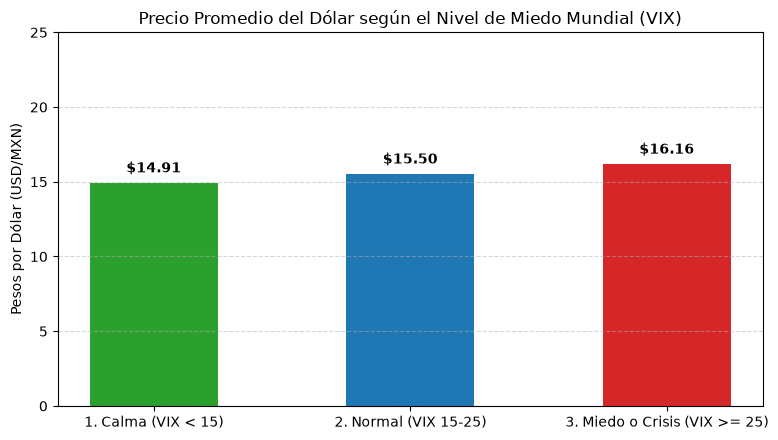

In [3]:
# Gráfica de la Pregunta 1: Precio promedio del dólar según la situación mundial
df_p1 = res_1.toPandas()

plt.figure(figsize=(8, 4.5))
barras = plt.bar(df_p1["situacion_mundial"], df_p1["dolar_promedio"], color=["#2ca02c", "#1f77b4", "#d62728"], width=0.5)
plt.title("Precio Promedio del Dólar según el Nivel de Miedo Mundial (VIX)", fontsize=12)
plt.ylabel("Pesos por Dólar (USD/MXN)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.ylim(0, 25)

# Agregamos el número exacto arriba de cada barra
for b in barras:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2., h + 0.5, f"${h:.2f}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()


**Respuesta a la Pregunta 1:**
* Cuando el mundo está en **calma**, el dólar es más barato en México: costó en promedio **$14.91 pesos**.
* Cuando hay **miedo o crisis internacional**, el dólar sube con fuerza: costó en promedio **$16.6 pesos** (e incluso llegó a pasar de los $24 pesos durante la pandemia de 2020).
* El dólar sube casi de inmediato en México cada vez que hay problemas o nerviosismo en los mercados del mundo, esto puede deberse a que los inversionistas buscan proteger su dinero comprando dólares.


### Pregunta 2: ¿Si la bolsa de Estados Unidos sube, también crece la industria en México?
Calculamos el promedio anual de la bolsa de Estados Unidos (S&P 500) y de la producción industrial de México (`Actividades secundarias`) para ver si avanzan juntas a lo largo de los años.


In [4]:
query_2 = """
SELECT 
    PERIODO,
    ROUND(SP500_PROMEDIO, 1) AS bolsa_eeuu,
    ROUND(`Actividades secundarias`, 2) AS industria_mexicana
FROM macro_mexico
ORDER BY PERIODO ASC
"""

res_2 = spark.sql(query_2)
print("Vista previa mensual (primeros 20 meses):")
res_2.show(20, truncate=False)


Vista previa mensual (primeros 20 meses):
+----------+----------+------------------+
|PERIODO   |bolsa_eeuu|industria_mexicana|
+----------+----------+------------------+
|2003-01-01|895.8     |80.86             |
|2003-02-01|837.6     |80.45             |
|2003-03-01|846.6     |82.97             |
|2003-04-01|890.0     |81.71             |
|2003-05-01|936.0     |81.98             |
|2003-06-01|988.0     |81.69             |
|2003-07-01|992.5     |83.64             |
|2003-08-01|989.5     |83.78             |
|2003-09-01|1019.4    |85.2              |
|2003-10-01|1038.7    |85.74             |
|2003-11-01|1049.9    |79.47             |
|2003-12-01|1080.6    |83.0              |
|2004-01-01|1132.5    |83.36             |
|2004-02-01|1143.4    |82.13             |
|2004-03-01|1124.0    |88.32             |
|2004-04-01|1133.1    |85.66             |
|2004-05-01|1102.8    |84.46             |
|2004-06-01|1132.8    |85.83             |
|2004-07-01|1105.8    |85.9              |
|2004-08-01|

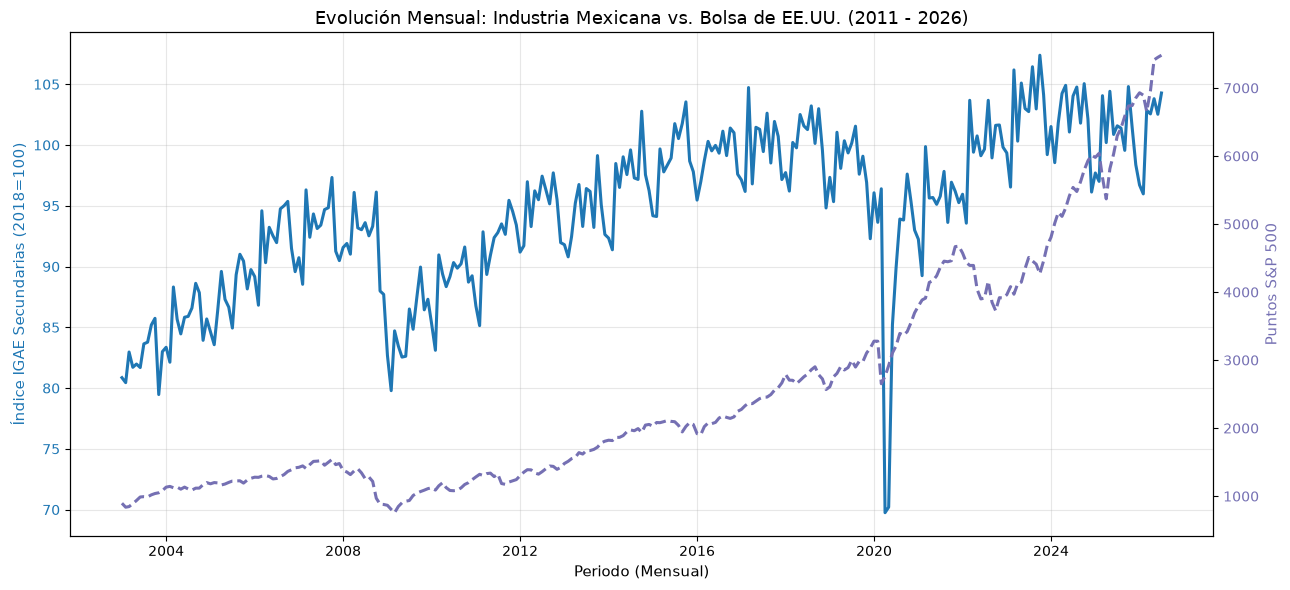

In [5]:
# Gráfica de la Pregunta 2
df_mensual = res_2.toPandas()
df_mensual["PERIODO"] = pd.to_datetime(df_mensual["PERIODO"])

fig, ax1 = plt.subplots(figsize=(13, 6))

# Eje izquierdo (Azul): Industria Mexicana
color_ind = "#1f77b4"
ax1.plot(
    df_mensual["PERIODO"], 
    df_mensual["industria_mexicana"], 
    color=color_ind, 
    lw=2.2, 
    label="Industria Mexicana (IGAE Secundarias)"
)
ax1.set_xlabel("Periodo (Mensual)", fontsize=11)
ax1.set_ylabel("Índice IGAE Secundarias (2018=100)", color=color_ind, fontsize=11)
ax1.tick_params(axis="y", labelcolor=color_ind)
ax1.grid(True, alpha=0.3)

# Eje derecho (Morado): S&P 500
ax2 = ax1.twinx()
color_sp = "#7570b3"
ax2.plot(
    df_mensual["PERIODO"], 
    df_mensual["bolsa_eeuu"], 
    color=color_sp, 
    lw=2.2, 
    linestyle="--", 
    label="Bolsa EE.UU. (S&P 500 Promedio)"
)
ax2.set_ylabel("Puntos S&P 500", color=color_sp, fontsize=11)
ax2.tick_params(axis="y", labelcolor=color_sp)

plt.title("Evolución Mensual: Industria Mexicana vs. Bolsa de EE.UU. (2011 - 2026)", fontsize=13)
fig.tight_layout()
plt.show()

**Respuesta a la Pregunta 2:**
* **Sí tienen relación:** En los años en que la economía de Estados Unidos crece y su bolsa sube, las fábricas y maquiladoras mexicanas también producen más para exportarles mercancías.
* **La caída de 2020:** En el año de la pandemia (2020), ambas series cayeron juntas debido al cierre de actividades y fábricas.
* **Diferencia de velocidad:** La bolsa de Estados Unidos subió mucho más rápido en los últimos años (pasó de unos 1,200 puntos a más de 5,000), mientras que la industria mexicana creció a un paso más moderado y estable.


### Pregunta 3: ¿El gobierno mexicano gana más de lo que gasta o gasta más de lo que tiene?
Sumamos los ingresos y los gastos reales del gobierno por cada año (ya sin el efecto de la inflación) y calculamos la diferencia: si el resultado es negativo, significa que gastó más de lo que ganó (déficit).


In [6]:
query_3 = """
SELECT 
    YEAR(PERIODO) AS anio,
    ROUND(SUM(INGRESOS_REALES) / 1000000, 1) AS ingresos_totales_mdp,
    ROUND(SUM(GASTOS_REALES) / 1000000, 1) AS gastos_totales_mdp,
    ROUND((SUM(INGRESOS_REALES) - SUM(GASTOS_REALES)) / 1000000, 1) AS diferencia_anual_mdp
FROM macro_mexico
GROUP BY YEAR(PERIODO)
ORDER BY anio ASC
"""

res_3 = spark.sql(query_3)
res_3.show(16, truncate=False)


+----+--------------------+------------------+--------------------+
|anio|ingresos_totales_mdp|gastos_totales_mdp|diferencia_anual_mdp|
+----+--------------------+------------------+--------------------+
|2003|2986.9              |3246.5            |-259.6              |
|2004|3197.5              |3452.3            |-254.8              |
|2005|3418.0              |3657.8            |-239.9              |
|2006|3647.4              |4057.5            |-410.1              |
|2007|3844.3              |4326.1            |-481.8              |
|2008|4385.7              |4777.3            |-391.7              |
|2009|4056.7              |4583.5            |-526.8              |
|2010|4052.2              |4746.9            |-694.8              |
|2011|4368.2              |5054.1            |-685.9              |
|2012|4439.6              |5184.9            |-745.3              |
|2013|4711.6              |5392.1            |-680.5              |
|2014|4839.2              |5655.7            |-8

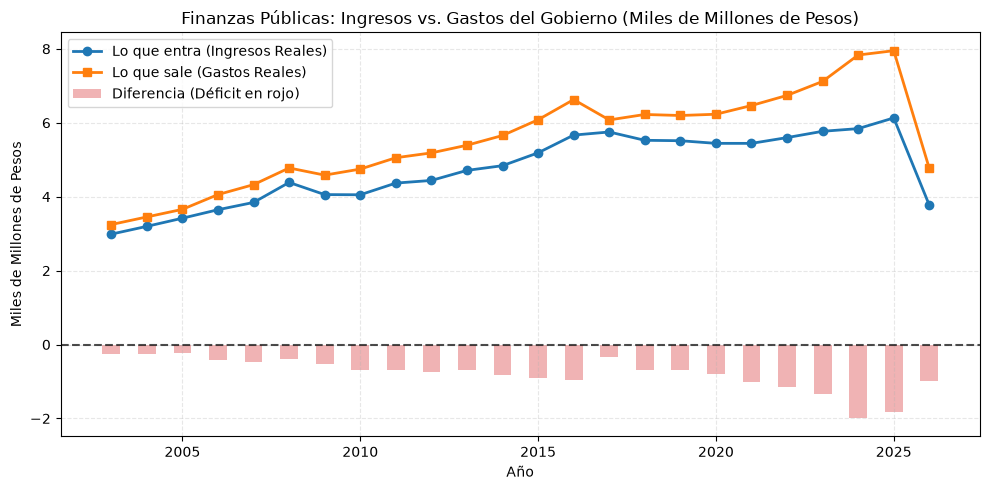

In [7]:
# Gráfica de la Pregunta 3: Ingresos vs Gastos y la diferencia (déficit)
df_p3 = res_3.toPandas()

plt.figure(figsize=(10, 5))
plt.plot(df_p3["anio"], df_p3["ingresos_totales_mdp"] / 1000, marker="o", label="Lo que entra (Ingresos Reales)", color="#1f77b4", linewidth=2)
plt.plot(df_p3["anio"], df_p3["gastos_totales_mdp"] / 1000, marker="s", label="Lo que sale (Gastos Reales)", color="#ff7f0e", linewidth=2)
plt.bar(df_p3["anio"], df_p3["diferencia_anual_mdp"] / 1000, label="Diferencia (Déficit en rojo)", color="#d62728", alpha=0.35, width=0.5)

plt.axhline(0, color="black", linestyle="--", alpha=0.7)
plt.title("Finanzas Públicas: Ingresos vs. Gastos del Gobierno (Miles de Millones de Pesos)", fontsize=12)
plt.xlabel("Año")
plt.ylabel("Miles de Millones de Pesos")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


**Respuesta a la Pregunta 3:**
* **Se gasta más de lo que recibe:** En todos los puntos los gastos fueron mayores que los ingresos (la barra roja siempre está por debajo de cero).
* **Los ingresos casi no crecen:** Al quitar la inflación, el dinero que recauda el gobierno se ha mantenido bastante parejo a lo largo de los años (alrededor de 4 a 5 billones de pesos anuales).
* **El gasto se disparó en los últimos años:** A partir de 2022, 2023 y 2024, el gasto creció mucho más rápido que los ingresos, haciendo que el faltante de dinero (déficit) sea el más grande de todo el periodo analizado.


## 3. Conclusiones Generales del Proyecto

Después de analizar los datos de 2011 a 2026, podemos contestar con total claridad si la economía del mundo afecta a México:

1. **El dólar es el primero en reaccionar:** Cada vez que hay una crisis o pánico en el mundo, el peso mexicano pierde valor casi de inmediato. En tiempos tranquilos el dólar rondaba los 15 pesos, pero en crisis subió por encima de los 20 y hasta 24 pesos.
2. **Nuestras fábricas dependen de Estados Unidos:** La industria mexicana (fábricas, carros, electrónicos) sube o baja de la mano con la economía y las empresas de Estados Unidos. Si a ellos les va bien, a nuestras fábricas también les va bien porque les compran más productos.
3. **Las cuentas del gobierno dependen más de decisiones internas:** Aunque una crisis internacional complica las cosas, el gran problema del dinero del gobierno (gastar más de lo que tiene) se debe a que los gastos internos subieron mucho en los últimos años, mientras que los ingresos reales se quedaron estancados.


## 4. Desacoplamiento: Trabajo del Pipeline vs. Consultas

Siguiendo lo visto en la **Clase 12**, separamos el trabajo pesado del análisis diario:

| Trabajo | ¿Cuándo se hace? | ¿Qué se hizo? |
| :--- | :--- | :--- |
| **Pipeline (Se hace una sola vez)** | Al preparar los datos | Lee los archivos crudos, quita datos malos, empareja las fechas mes con mes (`PERIODO`) y une las tres fuentes en una sola tabla limpia (`proyecto_integrado_mensual.parquet`). |
| **Consultas SQL (Se hace cada vez que queremos analizar)** | Al consultar | Hacemos preguntas específicas con `SELECT`, agrupamos por año, filtramos por niveles de miedo (`VIX`) y creamos las gráficas al momento sin tener que volver a limpiar los datos desde cero. |
